# Lab Avanzado
#### Mauricio Martinez, Alexis Aguilar
#### Terminado al Enero 2025


#### Restar la imagen mediana y verificar el valor de una carga en un pixel antes y despues.

In [45]:
from functions_py import *
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.stats import chisquare as chisquare
import pickle

#### Formato de Graficas

In [46]:
plt.rcParams.update({
    "image.origin": "lower",
    "image.aspect": 1,
    #"text.usetex": True,
    "grid.alpha": .5,
    "axes.linewidth":2,
    "lines.linewidth" : 1,
    "font.size":    15.0,
    "xaxis.labellocation": 'right',  # alignment of the xaxis label: {left, right, center}
    "yaxis.labellocation": 'top',  # alignment of the yaxis label: {bottom, top, center}
    "xtick.top":           True ,  # draw ticks on the top side
    "xtick.major.size":    8    ,# major tick size in points
    "xtick.minor.size":    4      ,# minor tick size in points
    "xtick.direction":     'in',
    "xtick.minor.visible": True,
    "ytick.right":           True ,  # draw ticks on the top side
    "ytick.major.size":    8    ,# major tick size in points
    "ytick.minor.size":    4      ,# minor tick size in points
    "ytick.direction":     'in',
    "ytick.minor.visible": True,
    "ytick.major.width":   2   , # major tick width in points
    "ytick.minor.width":   1 ,
    "xtick.major.width":   2   , # major tick width in points
    "xtick.minor.width":   1 ,
    "legend.framealpha": 0 ,
    "legend.loc": 'best',

})

# Microchip images

## Raw Image

Filename: /home/oem/datosFits/Data_2023/reverse_OS/proc_skp_m-009_microchip_T_170__NSAMP_1_NROW_650_NCOL_800_EXPOSURE_120_NBINROW_1_NBINCOL_1_img_832.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     165   (800, 650)   float32   
  1                1 ImageHDU       164   (800, 650)   float32   
  2                1 ImageHDU       164   (800, 650)   float32   
  3                1 ImageHDU       164   (800, 650)   float32   
None
----------------


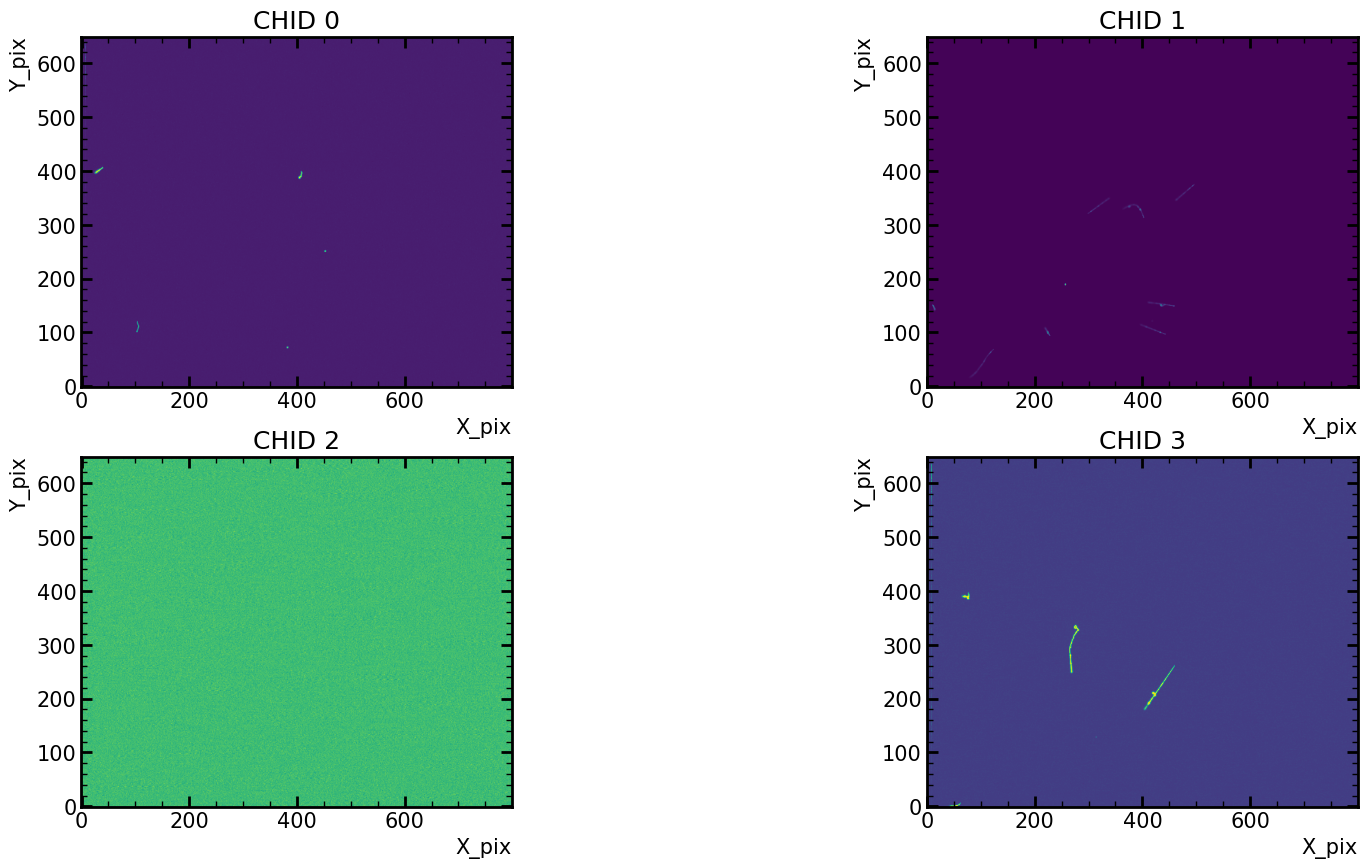

In [47]:
# ICN
#path='/home/oem/datosFits/Fe55_test2025/proc_skp_m-009_microchip_T_170__Vv82_NSAMP_324_NROW_400_NCOL_700_EXPOSURE_0_NBINROW_1_NBINCOL_1_img_258.fits'
# LapTop Mau
# path='/home/mauricio/datosFits/spuriousCharge/Microchip/14AUG23/proc_skp_module24_MITLL01_externalVr-4_Vv2_T140__NSAMP225_NROW650_NCOL700_EXPOSURE0_NBINROW1_NBINCOL1_img109.fits'
#path='/home/oem/datosFits/serialRegEvents/13OCT23/All/nsamp_324/proc_skp_m-009_microchip_T_170__Vv82_NSAMP_324_NROW_650_NCOL_700_EXPOSURE_0_NBINROW_1_NBINCOL_1_img_103.fits'
#path_img_nsamp_1
path='/home/oem/datosFits/Data_2023/reverse_OS/proc_skp_m-009_microchip_T_170__NSAMP_1_NROW_650_NCOL_800_EXPOSURE_120_NBINROW_1_NBINCOL_1_img_832.fits'
hdu_list = fits.open(path)
print(hdu_list.info())
print('----------------')
# hdu_list[0].header
plt.figure(figsize=(20,10))
for i in range(4):
    plt.subplot(2,2,i+1)
    plt.imshow(hdu_list[i].data)
    plt.title('CHID '+str(i))
    plt.ylabel('Y_pix')
    plt.xlabel('X_pix')
plt.show()

In [48]:
irow=302
icol=115
hdu_list[i].data[irow,icol]

-2224.0

In [49]:
hdu_list[i].header['NCOL']

'800'

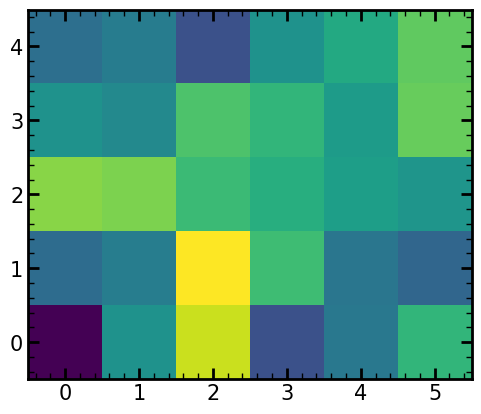

In [50]:
NROW=int(hdu_list[0].header['NROW'])
NCOL=int(hdu_list[0].header['NCOL'])
xlow=231
xhi=278
ylow=134
yhi=197
plt.imshow(hdu_list[0].data[113:118,300:306])

## Carga de un pixel en irow, icol

In [51]:
irow=117     # Y
icol=302     # X
Qij=hdu_list[0].data[irow-1,icol-1]
print(Qij)

6898.0


## Mediana del OverScan del renglon irow

In [ ]:
irow=117
icolOS_low=550
icolOS_hi=NCOL
np.median(hdu_list[0].data[irow-1,icolOS_low:icolOS_hi])

irow=117     # Y
icol=302     # X
Qij=hdu_list[0].data[irow-1,icol-1]
print(Qij)
Qos=Qij-np.median(hdu_list[0].data[irow-1,icolOS_low:icolOS_hi])
print(Qos)




6898.0
-295.0


In [53]:
new_image=np.zeros(shape=(NROW,NCOL))
for row in range(0,NROW,1):
    for col in range(0,icolOS_low, 1):
        new_image[row][col]=hdu_list[0].data[row][col]-np.median(hdu_list[0].data[row,icolOS_low:icolOS_hi])
    for col in range(icolOS_low, NCOL, 1):
        new_image[row][col]=hdu_list[0].data[row][col]-np.median(hdu_list[0].data[row,icolOS_low:icolOS_hi])






carga cruda Qij=6898.0
carga media sustraida=-295.0


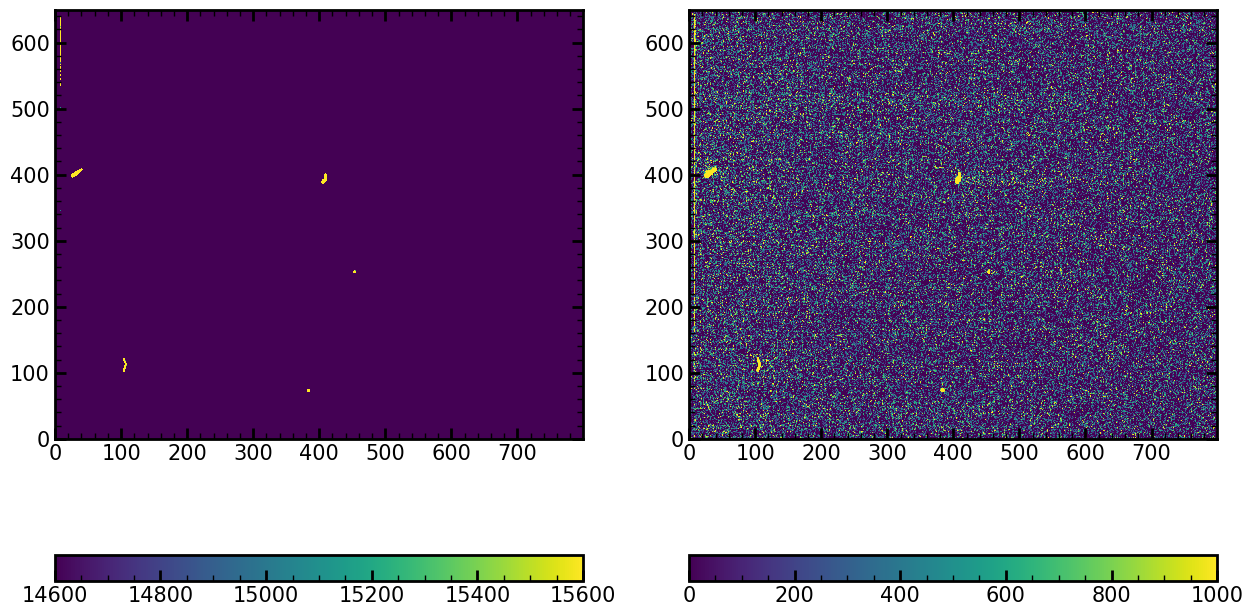

In [54]:
fig, (raw, median_sus)=plt.subplots(ncols=2, figsize=(15,10))
cruda=raw.imshow(hdu_list[0].data, vmin=14600, vmax=15600)
ok=median_sus.imshow(new_image, vmin=0, vmax=1000)

fig.colorbar(cruda, ax=raw, orientation='horizontal')
fig.colorbar(ok, ax=median_sus, orientation='horizontal')



irow=117     # Y
icol=302     # X
Qij_medianSus=new_image[irow-1,icol-1]
print("carga cruda Qij="+str(Qij))
print("carga media sustraida="+str(Qij_medianSus))

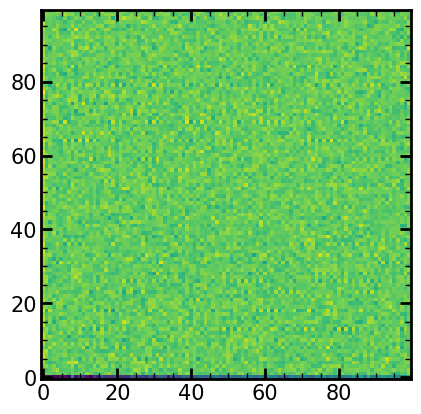

In [55]:
ROI_zero=hdu_list[0].data[0:100,0:100]
plt.imshow(ROI_zero)
list=ROI_zero.flatten()


In [60]:
file=open('file_med_inst2025.txt', 'a')
for dato in list:
    file.write(str(dato)+'\n')
file.close()